# РГР №3. Задание 1. Векторная модель текста

**Тема:** векторная модель текстов на основе мультимножества слов.

Для русского и английского языков выбрано по два текста из корпуса работы №1
(`wikimedia/wikipedia`, версия `20231101`). Тексты близки по размеру.

| Язык | Текст 1 | Текст 2 | Слов в тексте 1 | Слов в тексте 2 |
|---|---|---|---:|---:|
| Русский | Литва | Кавказские Минеральные Воды | 5 908 | 5 737 |
| Английский | Anarchism | Ayn Rand | 6 712 | 6 230 |

В задании требуется:

1. выполнить токенизацию;
2. применить нормализацию (лемматизацию);
3. удалить стоп-слова;
4. построить модель one-hot encoding;
5. построить модель TF (term frequency);
6. для one-hot модели определить пересечение мультимножеств;
7. для TF модели найти косинусный коэффициент.


In [1]:
from pathlib import Path
import sys
import json
from collections import Counter

import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'rgr3').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from rgr3 import vector_model as vm

pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 140)

metadata = json.loads((vm.DATA_DIR / 'texts_metadata.json').read_text(encoding='utf-8'))
for lang, items in metadata.items():
    print(lang.upper())
    for item in items:
        print(f"  {item['key']}: {item['title']} ({item['approx_words']:,} слов)")


RU
  ru_1: Литва (5,908 слов)
  ru_2: Кавказские Минеральные Воды (5,737 слов)
EN
  en_1: Anarchism (6,712 слов)
  en_2: Ayn Rand (6,230 слов)


## 1. Токенизация

Текст разбивается на слова регулярным выражением: для русского языка —
`[а-яё]+`, для английского — `[a-z]+`. Предварительно удаляются комбинируемые
знаки ударения, которые встречаются в русской Википедии, и все буквы
приводятся к нижнему регистру.


In [2]:
texts = {}
for lang, items in metadata.items():
    for item in items:
        path = vm.ROOT / item['file']
        texts[item['key']] = (lang, item, path.read_text(encoding='utf-8'))

raw_tokens = {}
rows = []
for key, (lang, item, text) in texts.items():
    tokens = vm.tokenize(text, lang)
    raw_tokens[key] = tokens
    rows.append({
        'key': key,
        'language': lang,
        'title': item['title'],
        'tokens': len(tokens),
        'unique_tokens': len(set(tokens)),
    })

display(pd.DataFrame(rows))
print('Первые 20 токенов ru_1:', raw_tokens['ru_1'][:20])
print('Первые 20 токенов en_1:', raw_tokens['en_1'][:20])


,key,language,title,tokens,unique_tokens
0,ru_1,ru,Литва,5332,2579
1,ru_2,ru,Кавказские Минеральные Воды,5446,2507
2,en_1,en,Anarchism,6790,1914
3,en_2,en,Ayn Rand,6236,1763


Первые 20 токенов ru_1: ['литва', 'официальное', 'название', 'литовская', 'республика', 'государство', 'расположенное', 'в', 'северной', 'европе', 'площадь', 'км', 'протяжённость', 'с', 'севера', 'на', 'юг', 'км', 'а', 'с']
Первые 20 токенов en_1: ['anarchism', 'is', 'a', 'political', 'philosophy', 'and', 'movement', 'that', 'is', 'skeptical', 'of', 'all', 'justifications', 'for', 'authority', 'and', 'seeks', 'to', 'abolish', 'the']


## 2. Нормализация текста

В качестве нормализации используется лемматизация библиотекой `simplemma`:
словоформы приводятся к начальной форме. Например, «Литвы» → «литва»,
«running» → «run».


In [3]:
normalized_tokens = {}
rows = []
for key, (lang, item, text) in texts.items():
    tokens = vm.lemmatize_tokens(raw_tokens[key], lang)
    normalized_tokens[key] = tokens
    rows.append({
        'key': key,
        'language': lang,
        'title': item['title'],
        'tokens': len(tokens),
        'unique_tokens': len(set(tokens)),
    })

display(pd.DataFrame(rows))

for key in ('ru_1', 'en_1'):
    changes = [
        (before, after)
        for before, after in zip(raw_tokens[key], normalized_tokens[key])
        if before != after
    ]
    print(f'{key}, примеры нормализации: {changes[:15]}')


,key,language,title,tokens,unique_tokens
0,ru_1,ru,Литва,5332,1832
1,ru_2,ru,Кавказские Минеральные Воды,5446,1750
2,en_1,en,Anarchism,6790,1602
3,en_2,en,Ayn Rand,6236,1537


ru_1, примеры нормализации: [('официальное', 'официальный'), ('литовская', 'литовский'), ('расположенное', 'расположенный'), ('северной', 'северный'), ('европе', 'европа'), ('км', 'километр'), ('севера', 'север'), ('км', 'километр'), ('запада', 'запад'), ('км', 'километр'), ('составляет', 'составлять'), ('занимает', 'занимать'), ('мире', 'мир'), ('численности', 'численность'), ('населения', 'население')]
en_1, примеры нормализации: [('is', 'be'), ('is', 'be'), ('justifications', 'justification'), ('seeks', 'seek'), ('institutions', 'institution'), ('claims', 'claim'), ('including', 'include'), ('states', 'state'), ('advocates', 'advocate'), ('societies', 'society'), ('associations', 'association'), ('reading', 'read'), ('is', 'be'), ('placed', 'place'), ('farthest', 'far')]


## 3. Удаление стоп-слов

Стоп-слова — это предлоги, союзы, частицы, местоимения, вспомогательные
глаголы и другие служебные слова. Используется список служебных слов из
РГР №2; он также лемматизируется, чтобы удалялись все словоформы. После
фильтрации удаляются одиночные буквы — артефакты токенизации.


In [4]:
filtered_tokens = {}
rows = []
for key, (lang, item, text) in texts.items():
    stops = vm.stopword_set(lang)
    tokens = [
        token for token in normalized_tokens[key]
        if token not in stops and len(token) >= 2
    ]
    filtered_tokens[key] = tokens
    rows.append({
        'key': key,
        'language': lang,
        'title': item['title'],
        'tokens_after_stopwords': len(tokens),
        'unique_tokens': len(set(tokens)),
    })

display(pd.DataFrame(rows))

for key in ('ru_1', 'ru_2', 'en_1', 'en_2'):
    top = Counter(filtered_tokens[key]).most_common(10)
    print(f'{key}: {top}')


,key,language,title,tokens_after_stopwords,unique_tokens
0,ru_1,ru,Литва,3990,1745
1,ru_2,ru,Кавказские Минеральные Воды,4106,1659
2,en_1,en,Anarchism,3880,1476
3,en_2,en,Ayn Rand,3554,1408


ru_1: [('год', 163), ('литва', 159), ('литовский', 96), ('страна', 36), ('язык', 32), ('население', 29), ('территория', 28), ('государство', 25), ('ссср', 18), ('княжество', 18)]
ru_2: [('вода', 120), ('минеральный', 87), ('год', 83), ('кавказский', 54), ('курорт', 52), ('кмв', 51), ('пятигорск', 37), ('источник', 37), ('район', 34), ('кисловодск', 28)]
en_1: [('anarchist', 160), ('anarchism', 116), ('state', 74), ('movement', 38), ('political', 24), ('group', 24), ('society', 22), ('form', 22), ('anti', 22), ('current', 22)]
en_2: [('rand', 175), ('american', 39), ('work', 33), ('philosopher', 32), ('novel', 29), ('review', 26), ('idea', 26), ('philosophy', 25), ('ayn', 23), ('writer', 23)]


## 4. Модель one-hot encoding

Для каждой пары текстов строится общий словарь (объединение словарей двух
текстов). Вектор текста содержит 1, если слово встречается в тексте, и 0 в
противном случае. Размерность вектора равна размеру общего словаря.


In [5]:
counters = {key: Counter(tokens) for key, tokens in filtered_tokens.items()}
pairs = {}

for lang, items in metadata.items():
    keys = [item['key'] for item in items]
    vocabulary = vm.build_vocabulary([counters[key] for key in keys])
    matrix = vm.one_hot_matrix([counters[key] for key in keys], vocabulary)
    pairs[lang] = {'keys': keys, 'vocabulary': vocabulary, 'one_hot': matrix}

    print(f'{lang}: размер словаря = {len(vocabulary):,}, '
          f'размер матрицы = {matrix.shape}, '
          f'единиц в матрице = {int(matrix.sum()):,}')
    display(pd.DataFrame(
        matrix[:, :10],
        index=keys,
        columns=vocabulary[:10],
    ))


ru: размер словаря = 2,992, размер матрицы = (2, 2992), единиц в матрице = 3,404


,аболина,абсолютный,август,авиалиния,авиационный,авиженис,австрией,автодорога,автомагистраль,автомобильный
ru_1,0,0,1,0,1,1,1,0,1,1
ru_2,1,1,1,1,0,0,0,1,1,1


en: размер словаря = 2,395, размер матрицы = (2, 2395), единиц в матрице = 2,884


,ability,able,abolish,abolition,abortion,absolute,abstentionism,academe,academia,academic
en_1,1,1,1,1,0,0,1,0,1,1
en_2,0,1,0,0,1,1,0,1,1,1


## 5. Модель TF (term frequency)

В TF-модели вес слова равен его относительной частоте в тексте:

$$\mathrm{TF}(w, d) = \frac{n_{w,d}}{\sum_{w'} n_{w',d}}$$

где $n_{w,d}$ — число вхождений слова $w$ в текст $d$. Векторы также
строятся в общем словаре пары текстов.


In [6]:
for lang, data in pairs.items():
    keys = data['keys']
    vocabulary = data['vocabulary']
    matrix = vm.tf_matrix([counters[key] for key in keys], vocabulary)
    data['tf'] = matrix

    print(f'{lang}: размер TF-матрицы = {matrix.shape}, '
          f'суммы весов по текстам = {matrix.sum(axis=1).round(6)}')

    rows = []
    for row, key in enumerate(keys):
        terms = sorted(zip(vocabulary, matrix[row]), key=lambda x: x[1], reverse=True)[:10]
        for rank, (word, value) in enumerate(terms, start=1):
            rows.append({'text': key, 'rank': rank, 'word': word, 'tf': round(float(value), 6)})
    display(pd.DataFrame(rows).pivot(index='rank', columns='text', values=['word', 'tf']))


ru: размер TF-матрицы = (2, 2992), суммы весов по текстам = [1. 1.]


word                     tf          
text         ru_1         ru_2      ru_1      ru_2
rank                                              
1             год         вода  0.040852  0.029226
2           литва  минеральный   0.03985  0.021189
3       литовский          год   0.02406  0.020214
4          страна   кавказский  0.009023  0.013151
5            язык       курорт   0.00802  0.012664
6       население          кмв  0.007268  0.012421
7      территория     источник  0.007018  0.009011
8     государство    пятигорск  0.006266  0.009011
9         великий        район  0.004511  0.008281
10      княжество   кисловодск  0.004511  0.006819

en: размер TF-матрицы = (2, 2395), суммы весов по текстам = [1. 1.]


word                     tf          
text       en_1         en_2      en_1      en_2
rank                                            
1     anarchist         rand  0.041237   0.04924
2     anarchism     american  0.029897  0.010974
3         state         work  0.019072  0.009285
4      movement  philosopher  0.009794  0.009004
5         group        novel  0.006186   0.00816
6     political         idea  0.006186  0.007316
7          anti       review   0.00567  0.007316
8       current   philosophy   0.00567  0.007034
9          form          ayn   0.00567  0.006472
10      society       writer   0.00567  0.006472

## 6. Пересечение мультимножеств для one-hot модели

Для one-hot векторов пересечение — это слова, которые есть в обоих текстах
(общие уникальные слова). Дополнительно для исходных мультимножеств слов
вычисляется пересечение с кратностями:

$$|M_1 \cap M_2| = \sum_w \min(n_{w,1}, n_{w,2}).$$

Также приводятся коэффициент Жаккара и косинус one-hot векторов.


In [7]:
rows = []
for lang, data in pairs.items():
    key_1, key_2 = data['keys']
    counter_1, counter_2 = counters[key_1], counters[key_2]

    common_words = set(counter_1) & set(counter_2)
    union_words = set(counter_1) | set(counter_2)
    intersection = counter_1 & counter_2
    jaccard = len(common_words) / len(union_words) if union_words else 0.0
    cosine_one_hot = vm.cosine_similarity(data['one_hot'][0], data['one_hot'][1])

    rows.append({
        'language': lang,
        'text_1': key_1,
        'text_2': key_2,
        'common_unique_words': len(common_words),
        'union_unique_words': len(union_words),
        'multiset_intersection': sum(intersection.values()),
        'jaccard': round(jaccard, 6),
        'cosine_one_hot': round(cosine_one_hot, 6),
    })

    print(f'{lang}: общих уникальных слов = {len(common_words):,}, '
          f'пересечение мультимножеств = {sum(intersection.values()):,}, '
          f'Жаккар = {jaccard:.4f}, косинус one-hot = {cosine_one_hot:.4f}')

    common_table = pd.DataFrame([
        {
            'word': word,
            'count_text_1': int(counter_1.get(word, 0)),
            'count_text_2': int(counter_2.get(word, 0)),
            'min_count': int(intersection.get(word, 0)),
        }
        for word in common_words
    ]).sort_values(['min_count', 'count_text_1'], ascending=False).head(10)
    display(common_table)

display(pd.DataFrame(rows))


ru: общих уникальных слов = 412, пересечение мультимножеств = 900, Жаккар = 0.1377, косинус one-hot = 0.2421


,word,count_text_1,count_text_2,min_count
2,год,163,83,83
24,территория,28,21,21
197,первый,15,14,14
390,часть,12,16,12
160,государственный,14,10,10
268,состав,12,10,10
154,край,10,14,10
283,февраль,10,8,8
129,город,8,17,8
185,один,8,10,8


en: общих уникальных слов = 489, пересечение мультимножеств = 1,061, Жаккар = 0.2042, косинус one-hot = 0.3392


,word,count_text_1,count_text_2,min_count
214,state,74,22,22
325,political,24,19,19
99,philosophical,15,14,14
44,late,13,19,13
323,century,20,12,12
17,include,12,21,12
363,first,11,14,11
114,take,15,10,10
200,libertarian,10,11,10
394,become,10,10,10


,language,text_1,text_2,common_unique_words,union_unique_words,multiset_intersection,jaccard,cosine_one_hot
0,ru,ru_1,ru_2,412,2992,900,0.137701,0.242145
1,en,en_1,en_2,489,2395,1061,0.204175,0.339207


## 7. Косинусный коэффициент для TF модели

Косинусная мера близости вычисляется по формуле

$$\cos(\mathbf{v}_1, \mathbf{v}_2) =
\frac{\mathbf{v}_1 \cdot \mathbf{v}_2}
{\|\mathbf{v}_1\| \, \|\mathbf{v}_2\|}.$$


In [8]:
rows = []
for lang, data in pairs.items():
    key_1, key_2 = data['keys']
    cosine_tf = vm.cosine_similarity(data['tf'][0], data['tf'][1])
    rows.append({
        'language': lang,
        'text_1': key_1,
        'text_2': key_2,
        'cosine_tf': round(cosine_tf, 6),
    })
    print(f'{lang}: косинус TF = {cosine_tf:.4f}')

display(pd.DataFrame(rows))


ru: косинус TF = 0.2838
en: косинус TF = 0.1874


,language,text_1,text_2,cosine_tf
0,ru,ru_1,ru_2,0.283754
1,en,en_1,en_2,0.187388


## 8. Визуализация топ-10 TF-термов

На графике показаны десять слов с наибольшим весом TF для каждого текста
после удаления стоп-слов.


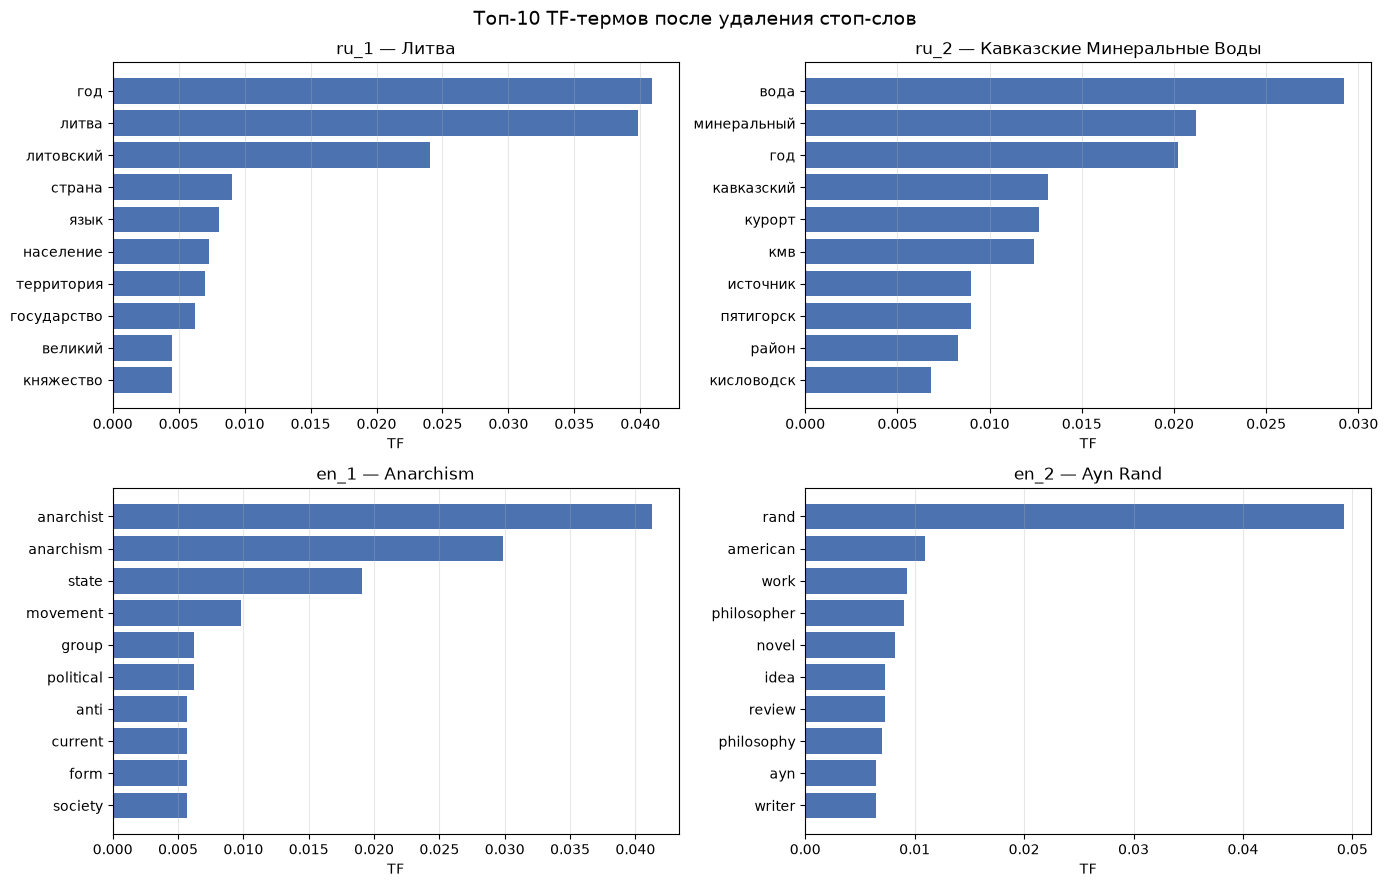

Сохранено: /home/dd/nlp_uni/rgr3/figures/task1_top_tf.png


In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_specs = [
    ('ru', 'ru_1', 0),
    ('ru', 'ru_2', 1),
    ('en', 'en_1', 0),
    ('en', 'en_2', 1),
]

for ax, (lang, key, row) in zip(axes.ravel(), plot_specs):
    data = pairs[lang]
    vocabulary = data['vocabulary']
    tf = data['tf'][row]
    top = sorted(zip(vocabulary, tf), key=lambda item: item[1], reverse=True)[:10][::-1]
    words = [word for word, _ in top]
    values = [value for _, value in top]

    ax.barh(words, values, color='#4C72B0')
    ax.set_title(f"{key} — {texts[key][1]['title']}")
    ax.set_xlabel('TF')
    ax.grid(axis='x', alpha=0.3)

fig.suptitle('Топ-10 TF-термов после удаления стоп-слов', fontsize=14)
fig.tight_layout()
figure_path = vm.ROOT / 'rgr3' / 'figures' / 'task1_top_tf.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=200, bbox_inches='tight')
plt.show()
print('Сохранено:', figure_path)


## 9. Итоговая таблица и сохранение результатов

Ниже ещё раз запускается полный расчёт из модуля `vector_model.py`; результаты
сохраняются в `rgr3/data/task1_results.json` и `rgr3/data/task1_summary.csv`.


In [10]:
vm.main()
display(pd.read_csv(vm.DATA_DIR / 'task1_summary.csv'))


[ru] Литва / Кавказские Минеральные Воды
  tokens after stop words: 3,990 / 4,106
  unique words: 1,745 / 1,659
  common unique words: 412
  multiset intersection: 900
  Jaccard: 0.1377
  cosine (one-hot): 0.2421
  cosine (TF): 0.2838

[en] Anarchism / Ayn Rand
  tokens after stop words: 3,880 / 3,554
  unique words: 1,476 / 1,408
  common unique words: 489
  multiset intersection: 1,061
  Jaccard: 0.2042
  cosine (one-hot): 0.3392
  cosine (TF): 0.1874



,language,text_1,text_2,tokens_1,tokens_2,unique_1,unique_2,common_unique,multiset_intersection,jaccard,cosine_one_hot,cosine_tf
0,ru,Литва,Кавказские Минеральные Воды,3990,4106,1745,1659,412,900,0.137701,0.242145,0.283754
1,en,Anarchism,Ayn Rand,3880,3554,1476,1408,489,1061,0.204175,0.339207,0.187388


## Вывод

В задании 1 построены две векторные модели для двух пар текстов.

- После токенизации, лемматизации и удаления стоп-слов в каждом тексте
  остаётся около 3,5–4,1 тыс. значимых слов; словари двух текстов пересекаются
  примерно на 410–490 уникальных слов.
- One-hot модель учитывает только наличие слова, но не его частоту. Для
  русской пары косинус one-hot равен ≈ 0,24, для английской — ≈ 0,34.
- TF-модель дополнительно учитывает относительную частоту слов. Для русской
  пары косинус TF равен ≈ 0,28, для английской — ≈ 0,19. Различие между
  моделями объясняется тем, что one-hot «сглаживает» вклад частых слов, а TF
  усиливает вклад слов, которые повторяются в тексте много раз.
- Пересечение мультимножеств (с учётом кратностей) больше числа общих
  уникальных слов: например, для русской пары — 900 против 412, для
  английской — 1 061 против 489. Это показывает, что общие слова часто
  повторяются в обоих текстах.
